In [3]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from sklearn.preprocessing import MinMaxScaler

# Q1

14.3
34.0
[14.3]
[34.]


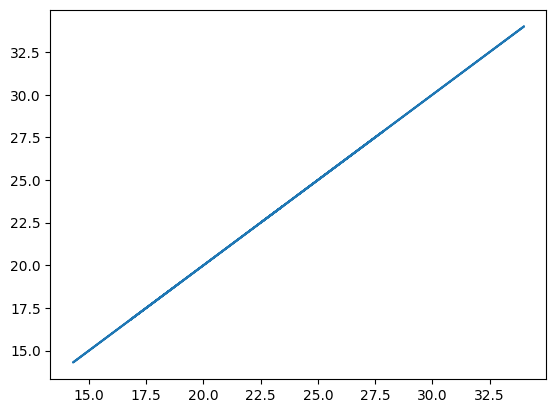

In [17]:
def min_max_scale(data, a, b):
    return a + (b - a) * ((data - min(data)) / (max(data) - min(data)))


x = np.random.normal(size=10)
x_tilde = min_max_scale(x, 14.3, 34)
print(min(x_tilde))
print(max(x_tilde))

scaler = MinMaxScaler(feature_range=(14.3, 34))
scaler.fit(x.reshape(-1, 1))
x2 = scaler.transform(x.reshape(-1, 1))
print(min(x2))
print(max(x2))

plt.plot(x_tilde, x2)
plt.show()

# Q2
From Figure 6.8, you might have gotten the impression that
the log-transform is much better than the square root trans-
form in making the data more normally distributed. That
conclusion is valid for that example, but it is not necessarily
true for data with other distributional characteristics.

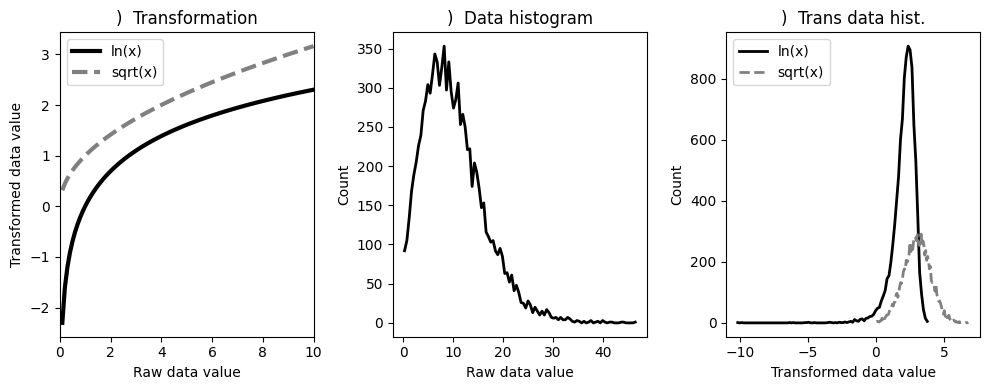

In [19]:
X = (np.random.randn(10000) + 3) ** 2

y_r, x_r = np.histogram(X, bins=100)  # r = raw
y_l, x_l = np.histogram(np.log(X), bins=100)  # l = log
y_s, x_s = np.histogram(np.sqrt(X), bins=100)  # s = sqrt

_, axs = plt.subplots(1, 3, figsize=(10, 4))

# theory
q = np.linspace(.1, 10, 100)
axs[0].plot(q, np.log(q), 'k', linewidth=3, label='ln(x)')
axs[0].plot(q, np.sqrt(q), '--', color='gray', linewidth=3, label='sqrt(x)')
axs[0].set(xlim=[0, 10], xlabel='Raw data value', ylabel='Transformed data value')
axs[0].set_title(r')  Transformation')
axs[0].legend()

# untransformed data
axs[1].plot((x_r[1:] + x_r[:-1]) / 2, y_r, 'k', linewidth=2)
axs[1].set(xlabel='Raw data value', ylabel='Count')
axs[1].set_title(r')  Data histogram')

axs[2].plot((x_l[1:] + x_l[:-1]) / 2, y_l, 'k', linewidth=2, label='ln(x)')
axs[2].plot((x_s[1:] + x_s[:-1]) / 2, y_s, '--', color='gray', linewidth=2, label='sqrt(x)')
axs[2].set(xlabel='Transformed data value', ylabel='Count')
axs[2].set_title(r')  Trans data hist.')
axs[2].legend()

plt.tight_layout()
plt.show()

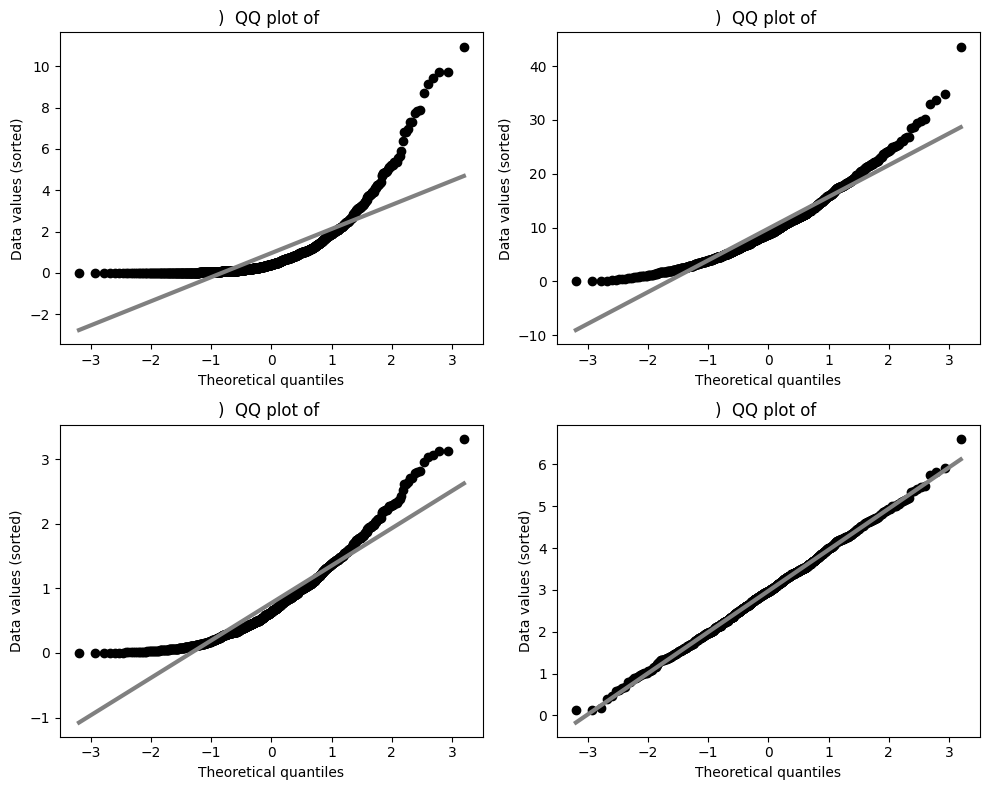

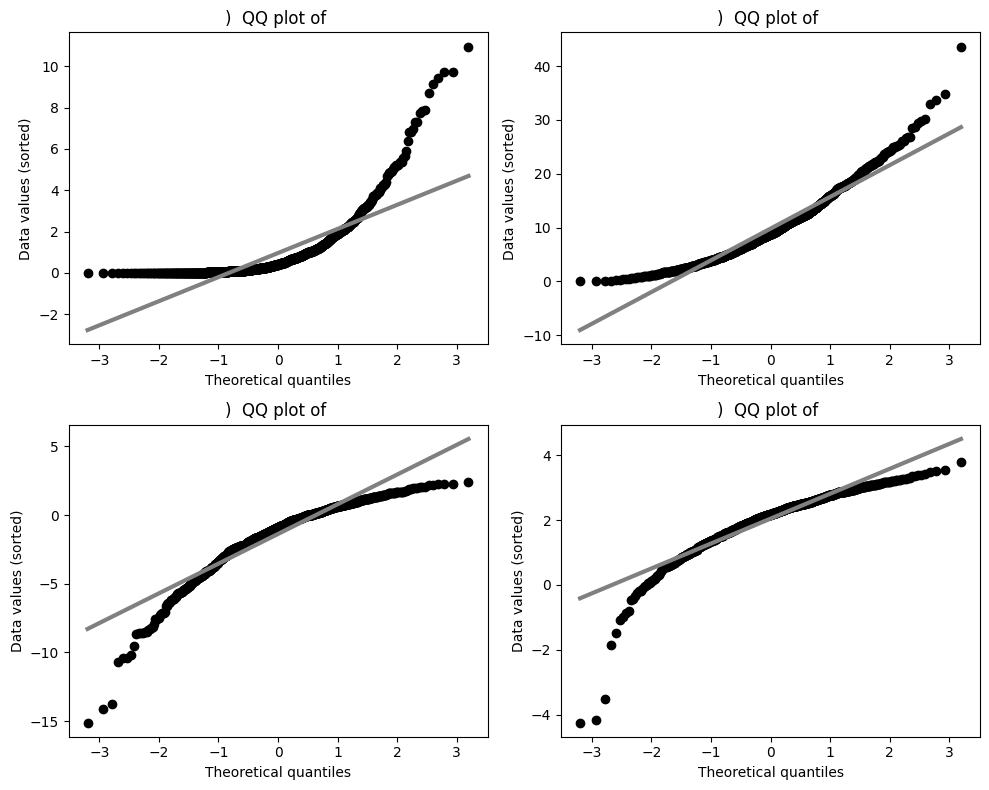

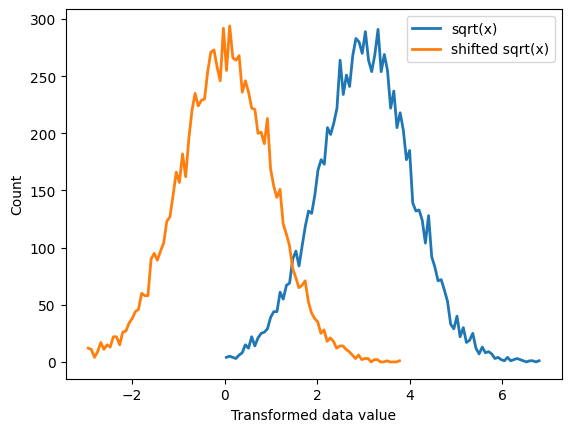

In [22]:
# data
X1 = (np.random.randn(1000) + 0) ** 2
X2 = (np.random.randn(1000) + 3) ** 2

# sqrt transform
X1s = np.sqrt(X1)
X2s = np.sqrt(X2)

_, axs = plt.subplots(2, 2, figsize=(10, 8))

# QQ plots
stats.probplot(X1, plot=axs[0, 0], fit=True)
stats.probplot(X2, plot=axs[0, 1], fit=True)

stats.probplot(X1s, plot=axs[1, 0], fit=True)
stats.probplot(X2s, plot=axs[1, 1], fit=True)

for a in axs.flatten():
    a.get_lines()[0].set_markerfacecolor('k')
    a.get_lines()[0].set_markeredgecolor('k')
    a.get_lines()[1].set_color('gray')
    a.get_lines()[1].set_linewidth(3)
    a.set_title(' ')
    a.set_ylabel('Data values (sorted)')

axs[0, 0].set_title(r')  QQ plot of ')
axs[0, 1].set_title(r')  QQ plot of ')
axs[1, 0].set_title(r')  QQ plot of ')
axs[1, 1].set_title(r')  QQ plot of ')

plt.tight_layout()
plt.savefig('trans_ex2.png')
plt.show()

# repeat for log transform
X1s = np.log(X1)
X2s = np.log(X2)

_, axs = plt.subplots(2, 2, figsize=(10, 8))

# QQ plots
stats.probplot(X1, plot=axs[0, 0], fit=True)
stats.probplot(X2, plot=axs[0, 1], fit=True)

stats.probplot(X1s, plot=axs[1, 0], fit=True)
stats.probplot(X2s, plot=axs[1, 1], fit=True)

for a in axs.flatten():
    a.get_lines()[0].set_markerfacecolor('k')
    a.get_lines()[0].set_markeredgecolor('k')
    a.get_lines()[1].set_color('gray')
    a.get_lines()[1].set_linewidth(3)
    a.set_title(' ')
    a.set_ylabel('Data values (sorted)')

axs[0, 0].set_title(r')  QQ plot of ')
axs[0, 1].set_title(r')  QQ plot of ')
axs[1, 0].set_title(r')  QQ plot of ')
axs[1, 1].set_title(r')  QQ plot of ')

plt.tight_layout()
plt.show()

# Shift the data to be mean-centered
X = (np.random.randn(10000) + 3) ** 2
Y = np.sqrt(X)
Y -= np.mean(Y)
y_s2, x_s2 = np.histogram(Y, bins=100)

plt.plot((x_s[1:] + x_s[:-1]) / 2, y_s, linewidth=2, label='sqrt(x)')
plt.plot((x_s2[1:] + x_s2[:-1]) / 2, y_s2, linewidth=2, label='shifted sqrt(x)')
plt.xlabel('Transformed data value')
plt.ylabel('Count')
plt.legend()
plt.show()



# Q7

The goal of this exercise is to explore the relationship between
standard deviation and MAD (median absolute difference) in
data distributions that become increasingly non-normal.

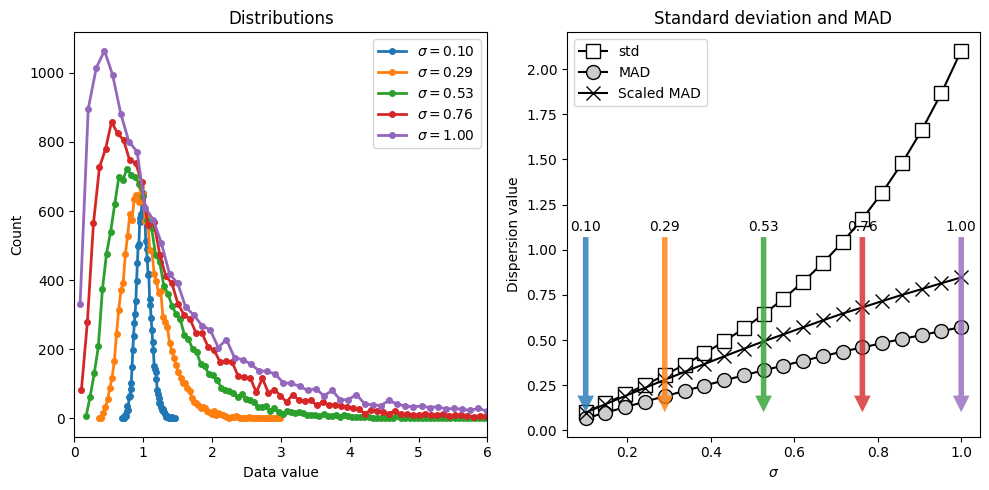

In [6]:
def my_stats(data):
    sd = np.std(data, ddof=1)
    mad = np.median(np.abs(data - np.median(data)))
    scaled_mad = mad / stats.norm.ppf(3 / 4)
    return sd, mad, scaled_mad


# -----------------------------
# generate data
# -----------------------------
np.random.seed(0)

N = 13524
X = np.random.randn(N)
sigmas = np.linspace(0.1, 1, 20)

data = []
M = np.zeros((len(sigmas), 3))

for i, s in enumerate(sigmas):
    d = np.exp(X * s)
    data.append(d)
    M[i, :] = my_stats(d)

# -----------------------------
# plotting
# -----------------------------
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

# ---- RIGHT: dispersion measures ----
axs[1].plot(sigmas, M[:, 0], 'ks-', markersize=10,
            markerfacecolor='w', label='std')

axs[1].plot(sigmas, M[:, 1], 'ko-', markersize=10,
            markerfacecolor=(.8, .8, .8), label='MAD')

axs[1].plot(sigmas, M[:, 2], 'kx-', markersize=10,
            label='Scaled MAD')

axs[1].set(
    xlabel=r'$\sigma$',
    ylabel='Dispersion value',
    title='Standard deviation and MAD'
)
axs[1].legend()

# ---- LEFT: selected distributions ----
selected_idx = np.linspace(0, len(sigmas) - 1, 5).astype(int)

for i in selected_idx:
    y, x = np.histogram(data[i], bins='fd')
    centers = (x[:-1] + x[1:]) / 2

    h = axs[0].plot(
        centers, y, '.-',
        linewidth=2, markersize=8,
        label=rf'$\sigma={sigmas[i]:.2f}$'
    )

    # vertical arrows on dispersion plot
    axs[1].annotate(
        f'{sigmas[i]:.2f}',
        xy=(sigmas[i], 0.1),
        xytext=(sigmas[i], axs[1].get_ylim()[1] / 2),
        horizontalalignment='center',
        arrowprops=dict(
            width=4,
            linewidth=0,
            color=h[0].get_color(),
            alpha=.8
        )
    )

axs[0].set(
    xlim=[0, 6],
    xlabel='Data value',
    ylabel='Count',
    title='Distributions'
)
axs[0].legend()

plt.tight_layout()
plt.show()


"You will recall that I wrote that the purpose of the scaling
factor was to help match the MAD with the standard devia-
tion for approximately normal distributions. This is evident
from the figure. First, notice that all three measures are very
similar for small values of σ, which correspond to data distri-
butions that are close to normal. As σ increases and the distri-
bution becomes more strongly positively skewed, the standard
deviation nonlinearly bends upwards while the MAD increases
roughly linearly. Scaled MAD is closer to standard deviation
up to σ values of around .3-.4 (based on visual inspection of
the plot). That’s a sensible result: It is nice for standard devi-
ation and MAD to be concordant for normal-like distributions,
but they should diverge as the distribution is increasingly non-
normal."

# Q8
The difference between two similarly non-normally distributed
variables can be roughly normally distributed. Let’s demon-
strate that in a simulation.

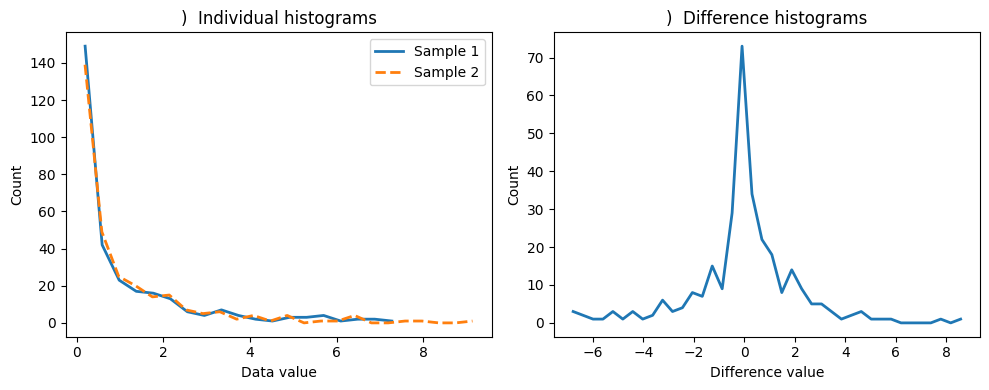

In [12]:
N = 300
s1 = np.random.randn(N) ** 2
s2 = np.random.randn(N) ** 2

dif = s2 - s1

y1, x1 = np.histogram(s1, bins='fd')
y2, x2 = np.histogram(s2, bins='fd')
yd, xd = np.histogram(dif, bins='fd')

# and plot
_, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].plot((x1[:-1] + x1[1:]) / 2, y1, linewidth=2, label='Sample 1')
axs[0].plot((x2[:-1] + x2[1:]) / 2, y2, '--', linewidth=2, label='Sample 2')
axs[0].set(xlabel='Data value', ylabel='Count')
axs[0].set_title(r')  Individual histograms')
axs[0].legend()

axs[1].plot((xd[:-1] + xd[1:]) / 2, yd, linewidth=2)
axs[1].set(xlabel='Difference value', ylabel='Count')
axs[1].set_title(r')  Difference histograms')

plt.tight_layout()
plt.show()

"Note that subtracting two variables is not always appropriate;
they should be paired measurements on the same scale. It
is also not mathematically necessarily the case that the dif-
ference between paired non-normally distributed variables will
be normally distributed. You have to check this in your data.
But when it works, it is simple and effective."